# Interplanetary Transfer Design

In [1]:
%load_ext autoreload
%autoreload 2
import sys
print(sys.executable)
import subprocess
result = subprocess.run([sys.executable, "-m", "pip", "show", "orbitkit"], capture_output=True, text=True)
print(result.stdout)

/Users/quaidgarton/Desktop/orbitaltoolkit/venv/bin/python
Name: orbitkit
Version: 0.1.0
Summary: Orbital mechanics toolkit: Lambert solver, trajectory propagator, and porkchop plot generator
Home-page: 
Author: Quaid Garton
Author-email: 
License: MIT
Location: /Users/quaidgarton/Desktop/orbitaltoolkit/venv/lib/python3.14/site-packages
Editable project location: /Users/quaidgarton/Desktop/orbitaltoolkit
Requires: matplotlib, numpy, scipy
Required-by: 



In [2]:
# Define and import constants
from pathlib import Path

from orbitkit.constants import planet_params, muSun

# Planet default
orbital_bodies = planet_params()

In [3]:
import numpy as np
import time
from orbitkit.propagator import propagate
# Numerically integrate 2 years to create positional data
tfin = 365 * 24 * 3600 *2 # [sec]
tspan = (0, tfin)
t_eval = np.linspace(tspan[0], tspan[1], (365+1)*2)
start_integration = time.perf_counter()
orbital_bodies = propagate(orbital_bodies, tspan, t_eval=t_eval, method='DOP853', show_progress=True) 
print(f"Integration took {time.perf_counter()-start_integration} seconds")
# Shape of orbital_bodies['Earth']['prop_pos'] is (N,3) same with vel and Mars data

  progress:   0.0%  (t = 0.000e+00 s)
  progress:  10.0%  (t = 6.338e+06 s)
  progress:  20.1%  (t = 1.265e+07 s)
  progress:  30.0%  (t = 1.893e+07 s)
  progress:  40.0%  (t = 2.523e+07 s)
  progress:  50.1%  (t = 3.157e+07 s)
  progress:  60.0%  (t = 3.785e+07 s)
  progress:  70.1%  (t = 4.418e+07 s)
  progress:  80.0%  (t = 5.048e+07 s)
  progress:  90.0%  (t = 5.677e+07 s)
  progress: 100.0%  (t = 6.307e+07 s)
Integration took 13.77372318700509 seconds


## Porkchop Plot

### Parse Data to examine, Determine desired departure and arrival windows

In [4]:
from orbitkit.lambert import transfer_angle, norm

# Likely dtheta range for this transfer is 44 degrees, so we will look for transfer angles between 40 and 50 degrees

n_steps = np.shape(orbital_bodies['Earth']['prop_pos'])[0]
print(f"Number of steps: {n_steps}")
viable_earth_index = np.zeros(n_steps, dtype=bool)
for i in range(0, n_steps): # i is index to earth pos in transfer window
        pos_e = orbital_bodies['Earth']['prop_pos'][i,:]
        vel_e = orbital_bodies['Earth']['prop_vel'][i,:]
        pos_m = orbital_bodies['Mars']['prop_pos'][i,:]
        vel_m = orbital_bodies['Mars']['prop_vel'][i,:]
        if 35 < np.degrees(transfer_angle(pos_e, pos_m, prograde=True)) < 55:
            viable_earth_index[i] = True

# Find likely arrival dates at Mars based on Departure dates from Earth and Hohmann transfer time
## Retrieve value of the indices of the viable earth departure dates ([0] simply returns the array instead of a tuple of one array)
earth_viable_idx = np.where(viable_earth_index)[0]
min_earth_idx, max_earth_idx = earth_viable_idx.min(), earth_viable_idx.max()

HOHMANN_TOF_GUESS = 259   # days -- computed Hohmann TOF for earth to mars transfer time
WINDOW_HALF_WIDTH = 60    # days -- how far around that estimate to search
## Viable Mars arrival dates based on Hohmann transfer time, with initial and final days as bounds
mars_lo = max(min_earth_idx + HOHMANN_TOF_GUESS - WINDOW_HALF_WIDTH, 0)
mars_hi = min(max_earth_idx + HOHMANN_TOF_GUESS + WINDOW_HALF_WIDTH, n_steps - 1)
## np.arange returns an np.array of integers from mars_lo to mars_hi inclusive
viable_mars_index = np.arange(mars_lo, mars_hi + 1)

earth_departure_pos = orbital_bodies['Earth']['prop_pos'][viable_earth_index,:]
earth_departure_vel = orbital_bodies['Earth']['prop_vel'][viable_earth_index,:]
mars_arrival_pos = orbital_bodies['Mars']['prop_pos'][viable_mars_index,:]
mars_arrival_vel = orbital_bodies['Mars']['prop_vel'][viable_mars_index,:]
## Mars departure positions only for visualization of departure angle
mars_departure_pos = orbital_bodies['Mars']['prop_pos'][viable_earth_index,:]

Number of steps: 732


#### Plot for visual sanity check on desired transfer angle range

In [5]:

from orbitkit.plotting import plot_plotly

# Plot the Earth and Mars orbits with the departure and arrival positions highlighted
print(np.shape(earth_departure_pos))
print(np.shape(mars_departure_pos))
print(np.shape(mars_arrival_pos))

plot_bodies = {'Earth_Departure' : orbital_bodies['Earth'], 'Mars_Departure' : orbital_bodies['Mars'], 
               'Mars_Arrival' : orbital_bodies['Mars'], 'Sun' : orbital_bodies['Sun']}
plot_bodies['Earth_Departure']['prop_pos'] = earth_departure_pos[:,:]
plot_bodies['Mars_Departure']['prop_pos'] = mars_departure_pos[:,:]
plot_bodies['Mars_Arrival']['prop_pos'] = mars_arrival_pos[:,:]
plot_plotly(plot_bodies, focus_body='Sun', zoom_radius=1.5*norm(orbital_bodies['Mars']['prop_pos'][0,:]))

(36, 3)
(36, 3)
(156, 3)


#### Create Ephemeris class out of departure and arrival windows

In [6]:
from orbitkit.ephem_io import create_ephemeris_from_pos_vel

day_indices = np.arange(n_steps)
earth_departure_days = day_indices[viable_earth_index]
mars_arrival_days = day_indices[viable_mars_index]

departure_window = create_ephemeris_from_pos_vel(earth_departure_pos, earth_departure_vel, name="Earth", jd=earth_departure_days)
arrival_window = create_ephemeris_from_pos_vel(mars_arrival_pos, mars_arrival_vel, name="Mars", jd=mars_arrival_days)

### Run Porkchop Plotter

On run 200/5617
On run 400/5617
On run 600/5617
On run 800/5617
On run 1000/5617
On run 1200/5617
On run 1400/5617
On run 1600/5617
On run 1800/5617
On run 2000/5617
On run 2200/5617
On run 2400/5617
On run 2600/5617
On run 2800/5617
On run 3000/5617
On run 3200/5617
On run 3400/5617
On run 3600/5617
On run 3800/5617
On run 4000/5617
On run 4200/5617
On run 4400/5617
On run 4600/5617
On run 4800/5617
On run 5000/5617
On run 5200/5617
On run 5400/5617
On run 5600/5617
Elapsed time for deltaV calculation: 13.58 seconds


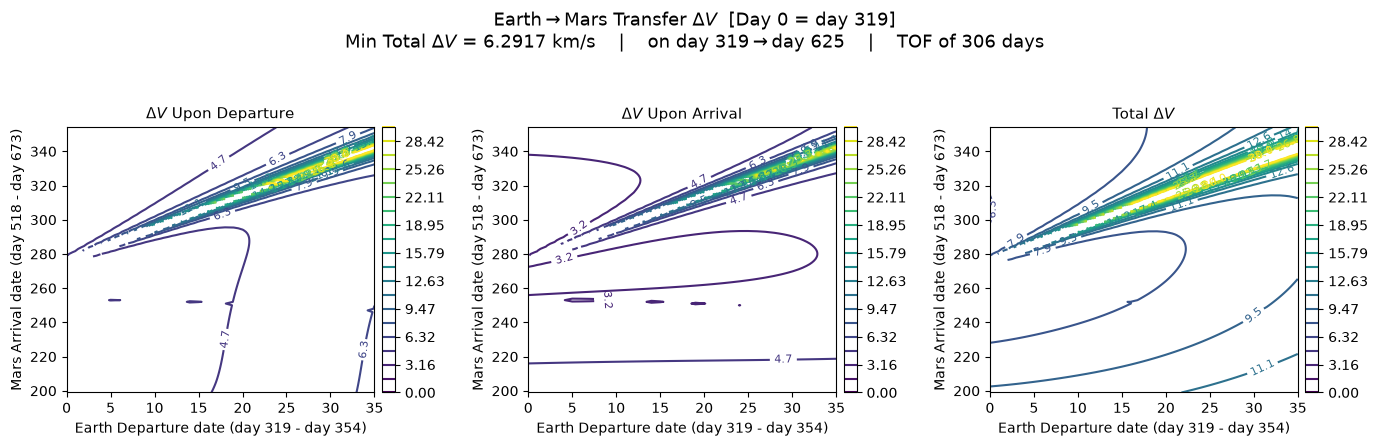

In [7]:
from orbitkit.porkchop_plotter import porkchop_grid_calculation, plot_porkchops
from orbitkit.lambert import lambert

# Calculate grid of dVs
dV1, dV2 = porkchop_grid_calculation(departure_window, arrival_window, muSun, lambert)

# Plot porkchop plots
plot_porkchops(departure_window, arrival_window, dV1, dV2)

### Pick Specific Arrival/Departure Date

## Solve Hyperbolic Transfers that Satisfy Lambert Transfer Arc

## Simulate Transfer

### Initialize Starting Values and Integrate

### Plot with Focus on Center of Transfer Arc

In [8]:
from orbitkit.plotting import plot_plotly